Variância explicada:
PC1: 54.21%
PC2: 20.40%
PC3: 19.39%
PC4: 3.94%
PC5: 2.07%

Variância acumulada nos 3 primeiros componentes: 93.99%


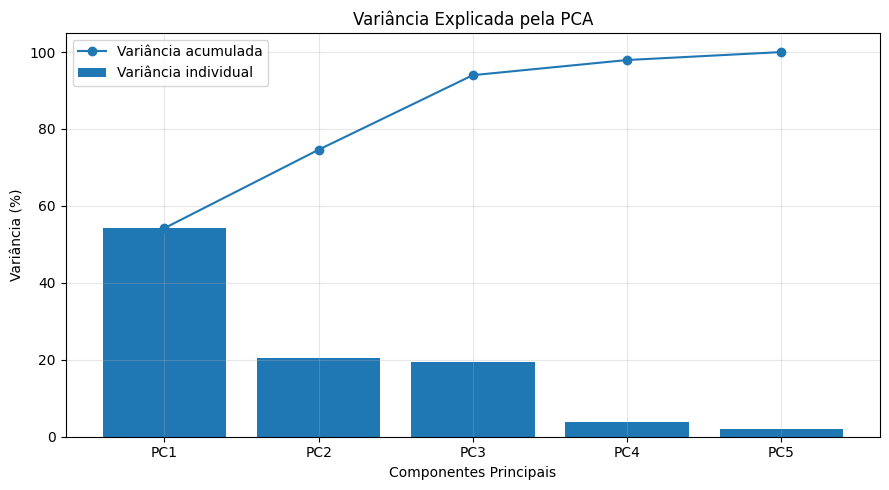


Contribuição das variáveis (Pesos):
                                                      PC1    PC2    PC3
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       -0.574 -0.103  0.079
UMIDADE RELATIVA DO AR, HORARIA (%)                 0.581 -0.085 -0.029
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI...  0.178  0.937  0.035
VENTO, VELOCIDADE HORARIA (m/s)                    -0.529  0.312  0.163
PRECIPITAÇÃO TOTAL, HORÁRIO (mm)                    0.145 -0.080  0.982


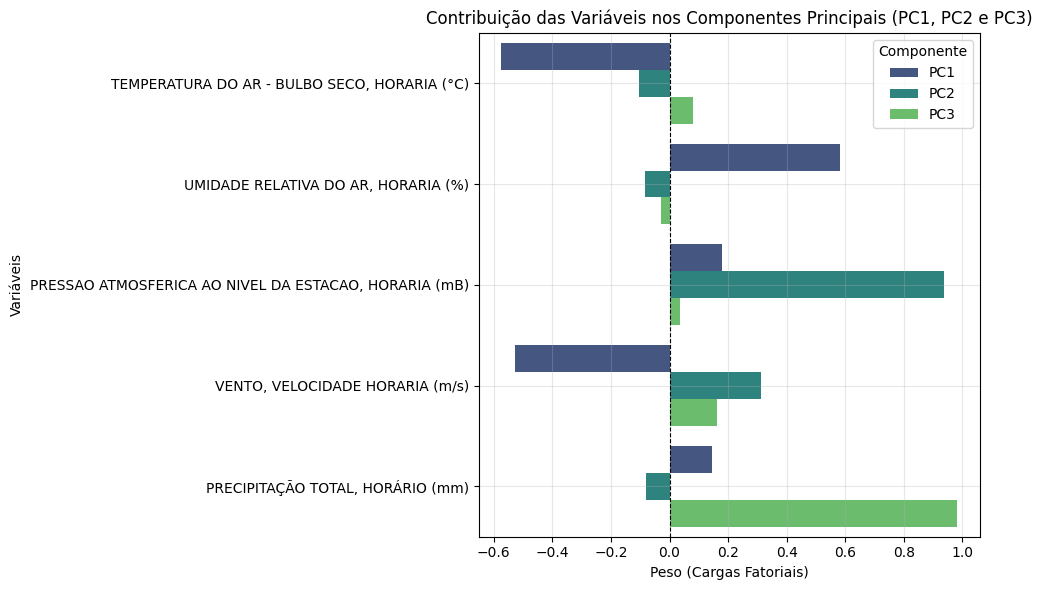

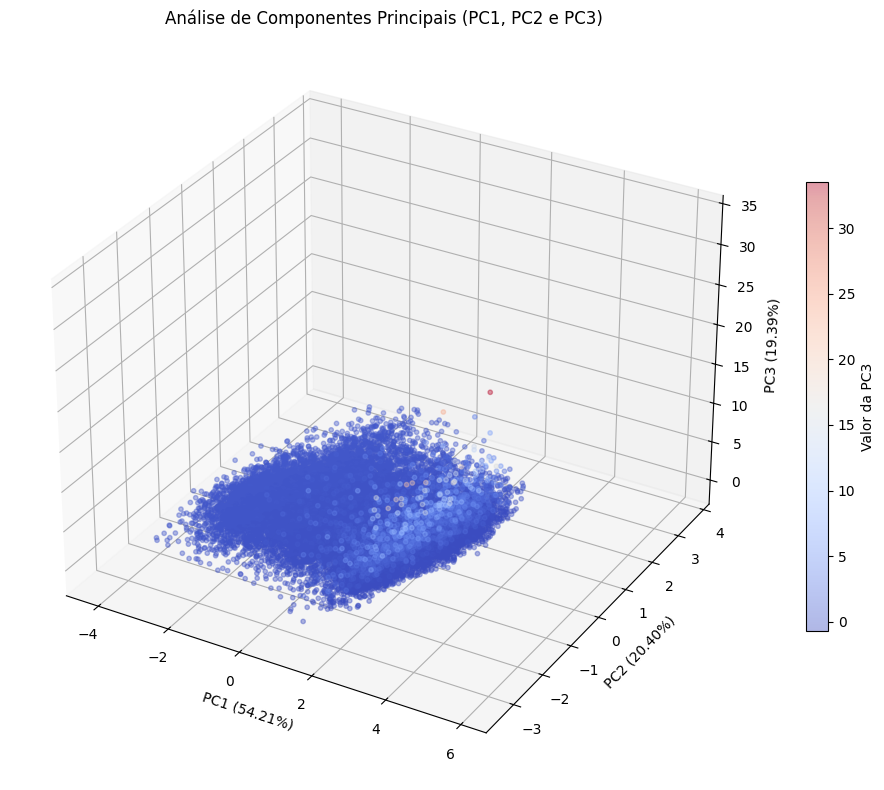


Estatísticas da Precipitação:
count    21659.000000
mean         0.253354
std          1.326874
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         45.600000
Name: PRECIPITAÇÃO TOTAL, HORÁRIO (mm), dtype: float64
Registros sem chuva: 85.01777552056882 %

Correlação dos dados originais:
                                                    TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)  \
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)                                                1.00   
UMIDADE RELATIVA DO AR, HORARIA (%)                                                        -0.88   
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI...                                         -0.34   
VENTO, VELOCIDADE HORARIA (m/s)                                                             0.74   
PRECIPITAÇÃO TOTAL, HORÁRIO (mm)                                                           -0.14   

                                                    UMIDADE REL

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('/content/data/df_recife_datetime.csv')

variaveis = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
]

dados = df[variaveis].copy()

dados = dados.apply(pd.to_numeric, errors='coerce')
dados = dados.dropna()

scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(dados)

pca = PCA()
componentes = pca.fit_transform(dados_padronizados)

variancia = pca.explained_variance_ratio_ * 100
variancia_acumulada = variancia.cumsum()

print('Variância explicada:')
for i, valor in enumerate(variancia):
    print(f'PC{i+1}: {valor:.2f}%')

print(f'\nVariância acumulada nos 3 primeiros componentes: {variancia_acumulada[2]:.2f}%')

# 1. Gráfico de Variância Explicada
plt.figure(figsize=(9, 5))
plt.bar(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia,
    label='Variância individual'
)
plt.plot(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia_acumulada,
    marker='o',
    label='Variância acumulada'
)
plt.title('Variância Explicada pela PCA')
plt.xlabel('Componentes Principais')
plt.ylabel('Variância (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. DataFrame de Contribuições (PC1, PC2 e PC3)
contribuicoes = pd.DataFrame(
    pca.components_[:3].T,
    index=variaveis,
    columns=['PC1', 'PC2', 'PC3']
)

print('\nContribuição das variáveis (Pesos):')
print(contribuicoes.round(3))

# 3. Gráfico de Contribuição das Variáveis por Componente
plt.figure(figsize=(10, 6))
contribuicoes_melted = contribuicoes.reset_index().melt(id_vars='index', var_name='Componente', value_name='Peso')
contribuicoes_melted.rename(columns={'index': 'Variável'}, inplace=True)

sns.barplot(
    data=contribuicoes_melted,
    x='Peso',
    y='Variável',
    hue='Componente',
    palette='viridis'
)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Contribuição das Variáveis nos Componentes Principais (PC1, PC2 e PC3)')
plt.xlabel('Peso (Cargas Fatoriais)')
plt.ylabel('Variáveis')
plt.grid(alpha=0.3)
plt.legend(title='Componente')
plt.tight_layout()
plt.show()

# 4. Scatter plot 3D dos Componentes Principais (PC1, PC2 e PC3)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    componentes[:, 0],
    componentes[:, 1],
    componentes[:, 2],
    c=componentes[:, 2],
    cmap='coolwarm',
    alpha=0.4,
    s=10
)

ax.set_title('Análise de Componentes Principais (PC1, PC2 e PC3)')
ax.set_xlabel(f'PC1 ({variancia[0]:.2f}%)')
ax.set_ylabel(f'PC2 ({variancia[1]:.2f}%)')
ax.set_zlabel(f'PC3 ({variancia[2]:.2f}%)')
fig.colorbar(sc, ax=ax, label='Valor da PC3', shrink=0.6)
plt.tight_layout()
plt.show()

# Informações Adicionais
print("\nEstatísticas da Precipitação:")
print(dados['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'].describe())
print(
    "Registros sem chuva:",
    (dados['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] == 0).mean() * 100,
    "%"
)
print("\nCorrelação dos dados originais:")
print(dados.corr().round(2))

### Investigação de Outliers dos Componentes Principais

In [ ]:
import numpy as np

# Criar DataFrame com as datas correspondentes aos dados sem valores nulos
indices_validos = dados.index
df_analise = df.loc[indices_validos].copy()

# Adicionar as coordenadas dos 3 primeiros componentes principais
df_analise['PC1'] = componentes[:, 0]
df_analise['PC2'] = componentes[:, 1]
df_analise['PC3'] = componentes[:, 2]

# Definir um limiar para classificar outliers (+3 desvios padrão)
for col in ['PC1', 'PC2', 'PC3']:
    limite_superior = df_analise[col].mean() + 3 * df_analise[col].std()
    limite_inferior = df_analise[col].mean() - 3 * df_analise[col].std()

    outliers = df_analise[(df_analise[col] > limite_superior) | (df_analise[col] < limite_inferior)]

    print(f"\n--- Outliers Detectados na {col} (Mais de 3 desvios padrão) ---")
    print(f"Total de outliers: {len(outliers)} de {len(df_analise)} registros.")

    # Exibir os 5 casos mais extremos (maior distância absoluta da média)
    outliers_extremos = outliers.reindex(
        (outliers[col] - df_analise[col].mean()).abs().sort_values(ascending=False).index
    )

    cols_exibicao = ['datetime', col] + variaveis
    display(outliers_extremos[cols_exibicao].head(5))



--- Outliers Detectados na PC1 (Mais de 3 desvios padrão) ---
Total de outliers: 1 de 21659 registros.


,datetime,PC1,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)","UMIDADE RELATIVA DO AR, HORARIA (%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)","VENTO, VELOCIDADE HORARIA (m/s)","PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
28242,2021-04-11 23:00:00,5.927217,23.4,94.0,1012.1,1.7,45.6



--- Outliers Detectados na PC2 (Mais de 3 desvios padrão) ---
Total de outliers: 49 de 21659 registros.


,datetime,PC2,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)","UMIDADE RELATIVA DO AR, HORARIA (%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)","VENTO, VELOCIDADE HORARIA (m/s)","PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
30676,2021-07-22 13:00:00,3.701118,27.5,65.0,1020.5,3.0,0.0
13530,2019-08-07 12:00:00,3.677412,26.5,65.0,1020.0,3.4,0.0
31031,2021-08-06 13:00:00,3.636468,26.9,65.0,1020.2,3.1,0.0
13506,2019-08-06 12:00:00,3.601451,25.3,73.0,1020.1,3.1,0.0
30677,2021-07-22 14:00:00,3.597080,28.2,63.0,1020.1,3.2,0.0



--- Outliers Detectados na PC3 (Mais de 3 desvios padrão) ---
Total de outliers: 292 de 21659 registros.


,datetime,PC3,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)","UMIDADE RELATIVA DO AR, HORARIA (%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)","VENTO, VELOCIDADE HORARIA (m/s)","PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
28242,2021-04-11 23:00:00,33.505541,23.4,94.0,1012.1,1.7,45.6
10438,2019-03-31 13:00:00,23.369062,24.3,92.0,1012.8,2.7,31.6
1833,2018-04-06 21:00:00,21.229331,23.9,91.0,1009.4,1.1,29.2
746,2018-02-20 14:00:00,20.034776,25.0,91.0,1010.4,0.8,27.6
9157,2019-02-06 04:00:00,19.571853,24.2,92.0,1010.8,0.8,27.0


## Resultados da Análise de Componentes Principais (PCA)

A aplicação da PCA sobre as variáveis meteorológicas (Temperatura, Umidade, Pressão, Vento e Precipitação) permitiu resumir a multidimensionalidade dos dados em eixos sintéticos principais, cujos resultados são detalhados abaixo:

Variância Explicada e Acumulada (Scree Plot):
  * O primeiro componente principal isoladamente é responsável por reter 54,21% da variância total dos dados.
  * O segundo componente PC2 explica cerca de 20,40%.
  * Juntos, PC1 e PC2 acumulam aproximadamente 74,61% de toda a informação contida nas cinco variáveis originais.
  * Nota-se também que os três primeiros componentes (PC1, PC2 e PC3) ultrapassam a marca de 90% de variância acumulada.

Distribuição Fatorial (Scatter Plot de PC1 vs PC2):
  * O gráfico de dispersão dos pontos no espaço formado por PC1 e PC2 demonstra uma grande densidade de registros concentrada próxima à região central (valores entre -2 e 2 nos eixos).
  * A forma da nuvem de pontos revela um comportamento contínuo das condições meteorológicas horárias, com alguns *outliers* (pontos mais isolados à direita e na parte inferior), correspondendo a momentos de registros atípicos ou eventos extremos de vento/precipitação na série histórica.